# Deeper QML: sharing response construction

This saved-data notebook independently audits the raw benchmark and displays its results.
It launches **no simulations or training jobs**. To reproduce training, use the commands
in `docs/deep_response.md`; a full run has 540 fresh-process attempts.

The new engine propagates Fourier coefficient states together. Qiskit receives the same
response degree, cache lifetime and checks, with fast runtime parameter binding. A second
Qiskit control also receives the same fixed-block matrices. This is a specialized
**classical CPU simulation** comparison, with no QPU execution or finite-shot claim.


In [1]:
from pathlib import Path
import hashlib, json, os, statistics, zipfile
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
%matplotlib inline

root = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "pyproject.toml").exists())
results = Path(os.environ.get("GROUPMEMORY_RESULTS", root / "results" / "deep-response"))
analysis = json.loads((results / "analysis.json").read_text())
config = json.loads((results / "config.json").read_text())
conditions = [c["id"] for c in config["conditions"]]
summary = {(r["condition"], r["method"]): r for r in analysis["summary"]}
comparisons = {(r["condition"], r["baseline"]): r for r in analysis["comparisons"]}
labels = {"group_spectral": "GroupMemory spectral", "group_grid": "Batched grid",
          "qiskit_response": "Qiskit runtime response", "qiskit_blocks": "Qiskit cached blocks",
          "classical_direct": "Direct state + tangent", "classical": "Classical task model"}
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
wins = {m: sum(comparisons[c, m]["descriptive_win"] for c in conditions)
        for m in ("qiskit_response", "qiskit_blocks")}
display(Markdown(f"**Completed: {analysis['successful']}/{analysis['planned']} attempts. "
    f"Matched correctness: {analysis['validation_passed']}/{analysis['validation_planned']} blocks.** "
    f"Qualifying descriptive wins: **{wins['qiskit_response']}/{len(conditions)}** against native "
    f"Qiskit response and **{wins['qiskit_blocks']}/{len(conditions)}** against cached-block Qiskit. "
    "Detailed timings, accuracy, negative cases and controls follow."))


**Completed: 540/540 attempts. Matched correctness: 90/90 blocks.** Qualifying descriptive wins: **3/6** against native Qiskit response and **5/6** against cached-block Qiskit. Detailed timings, accuracy, negative cases and controls follow.

## Context and methods

Six-qubit sensor and eight-qubit shared-angle classifiers use **2, 8 or 16 interleaved
layers**. Each layer has one occurrence of a shared trainable RY angle followed by a
fixed RX/RZ/CZ ring block; two fixed blocks alternate. There is one trainable circuit
angle and a fitted classical logistic head, with 12 updates. These are new architectures,
not deeper continuations of the prior shallow timing table.

For \(L\) occurrences, the state has \(L+1\) half-angle Fourier coefficients, and the
expectation has integer frequencies \(-L,\ldots,L\). The Qiskit and batched-grid controls
sample \(2L+1\) angles. The spectral implementation propagates coefficient states and
forms their autocorrelations. All response methods check every new derivative input at
two independent off-grid angles with absolute tolerance **1e-10**. Unseen forward-only
test inputs execute directly once.

Five seeds vary data, not circuit architecture. Each has three timing repeats, with
method order shuffled deterministically inside matched blocks. A descriptive win requires
five complete seeds, three matching repeats, every seed median faster and at least 5%
median paired saving. No statistical-significance or universal-crossover claim is made.


## Independent raw-record, source and checkpoint audit

In [2]:
verified = 0
for line in (results / "SHA256SUMS.txt").read_text().splitlines():
    digest, name = line.split("  ", 1)
    assert hashlib.sha256((results / name).read_bytes()).hexdigest() == digest, name
    verified += 1
with zipfile.ZipFile(results / "source_snapshot.zip") as archive:
    for name, digest in config["source_hashes"].items():
        assert hashlib.sha256(archive.read("group_memory_qml/" + name)).hexdigest() == digest
with zipfile.ZipFile(results / "raw_attempts.zip") as archive:
    raw_bytes = [archive.read(f"attempts/{i:05d}.json") for i in range(len(config["plan"]))]
    rows = [json.loads(value) for value in raw_bytes]
blocks = {}
for spec, row in zip(config["plan"], rows, strict=True):
    assert row["spec"] == spec and row["source_hashes"] == config["source_hashes"]
    assert row["status"] == "SUCCESS"
    assert 0 < row["application_s"] <= row["process_wall_s"]
    assert np.isfinite(row["process_wall_s"])
    blocks.setdefault((spec["condition"], spec["seed"], spec["repeat"]), {})[spec["method"]] = row
worst = 0.
for key, block in blocks.items():
    ref = block["qiskit_response"]
    assert len({r["diagnostics"]["dataset_sha256"] for r in block.values()}) == 1
    same = [r for m, r in block.items() if m != "classical"]
    for field in ("source_sha256", "architecture_sha256"):
        assert len({r["diagnostics"]["response"][field] for r in same}) == 1
    for row in same:
        error = float(np.max(np.abs(np.asarray(row["validation_vector"]) - ref["validation_vector"])))
        assert error <= 1e-10, (key, row["method"], error)
        worst = max(worst, error)
    assert len({block[m]["diagnostics"]["response"]["native_sha256"] for m in
                ("group_spectral", "group_grid", "qiskit_response", "qiskit_blocks")}) == 1
    assert len({tuple(block[m]["diagnostics"]["response"]["fixed_block_sha256"]) for m in
                ("group_spectral", "group_grid", "qiskit_blocks")}) == 1
for (cid, baseline), recorded in comparisons.items():
    ratios = []
    for seed in config["seeds"]:
        times = {}
        for method in ("group_spectral", baseline):
            times[method] = statistics.median(blocks[cid, seed, rep][method]["process_wall_s"]
                                               for rep in range(config["repeats"]))
        ratios.append(times[baseline] / times["group_spectral"])
    assert abs(statistics.median(ratios) - recorded["paired_speedup"]) < 1e-12
    assert (len(ratios) >= 5 and config["repeats"] >= 3 and min(ratios) > 1
            and statistics.median(1-1/r for r in ratios) >= .05) == recorded["descriptive_win"]
manifest = json.loads((results / "checkpoints" / "manifest.json").read_text())
cp_path = results / "checkpoints" / manifest["latest"]
assert hashlib.sha256(cp_path.read_bytes()).hexdigest() == manifest["latest_sha256"]
cp = json.loads(cp_path.read_text())
assert cp["completed_attempts"] == len(rows)
assert cp["config_sha256"] == hashlib.sha256((results / "config.json").read_bytes()).hexdigest()
assert cp["last_result_sha256"] == hashlib.sha256(raw_bytes[-1]).hexdigest()
auth = json.loads((results / "authorization.json").read_text())
assert cp["deadline_unix"] == manifest["deadline_unix"] == auth["deadline_unix"]
display(Markdown(f"Verified **{verified} packaged hashes**, **{len(rows)} raw records**, "
    f"**{len(blocks)} matched blocks**, all paired ratios and checkpoint links. "
    f"Maximum complete output/gradient/trajectory error: **{worst:.3g}**."))


Verified **33 packaged hashes**, **540 raw records**, **90 matched blocks**, all paired ratios and checkpoint links. Maximum complete output/gradient/trajectory error: **6.69e-14**.

## Results: full training cost and accuracy

Times are medians of seed medians. Each process includes imports, input preparation,
compilation, block construction and copies, response construction/checks, caching,
training, predictions, serialization and shutdown. The classical task model uses
different features; all other methods compute the same circuit model and trajectory.


In [3]:
methods = ("group_spectral", "group_grid", "qiskit_response", "qiskit_blocks", "classical_direct", "classical")
lines = ["| Workload | Spectral | Batched grid | Qiskit response | Qiskit blocks | Direct tangent | Classical task | Accuracy: same model / task |",
         "|---|---:|---:|---:|---:|---:|---:|---:|"]
for cid in conditions:
    times = [f"{summary[cid, m]['process_wall_s']:.3f} s" for m in methods]
    quality = f"{summary[cid, 'group_spectral']['accuracy']:.1%} / {summary[cid, 'classical']['accuracy']:.1%}"
    lines.append(f"| {cid} | " + " | ".join(times) + f" | {quality} |")
display(Markdown("\n".join(lines)))


| Workload | Spectral | Batched grid | Qiskit response | Qiskit blocks | Direct tangent | Classical task | Accuracy: same model / task |
|---|---:|---:|---:|---:|---:|---:|---:|
| deep_sensor-2 | 1.611 s | 1.607 s | 1.585 s | 1.775 s | 1.320 s | 1.306 s | 53.8% / 100.0% |
| deep_sensor-8 | 1.588 s | 1.586 s | 1.649 s | 1.681 s | 1.346 s | 1.269 s | 95.0% / 100.0% |
| deep_sensor-16 | 1.654 s | 1.583 s | 1.967 s | 1.874 s | 1.339 s | 1.268 s | 71.2% / 100.0% |
| deep_shared-2 | 1.612 s | 1.595 s | 1.591 s | 1.869 s | 1.353 s | 1.283 s | 100.0% / 100.0% |
| deep_shared-8 | 1.608 s | 1.611 s | 1.723 s | 2.714 s | 1.363 s | 1.274 s | 97.5% / 100.0% |
| deep_shared-16 | 1.713 s | 1.756 s | 2.156 s | 5.968 s | 1.462 s | 1.292 s | 100.0% / 100.0% |

### Paired speed ratios, including losing or inconclusive cases

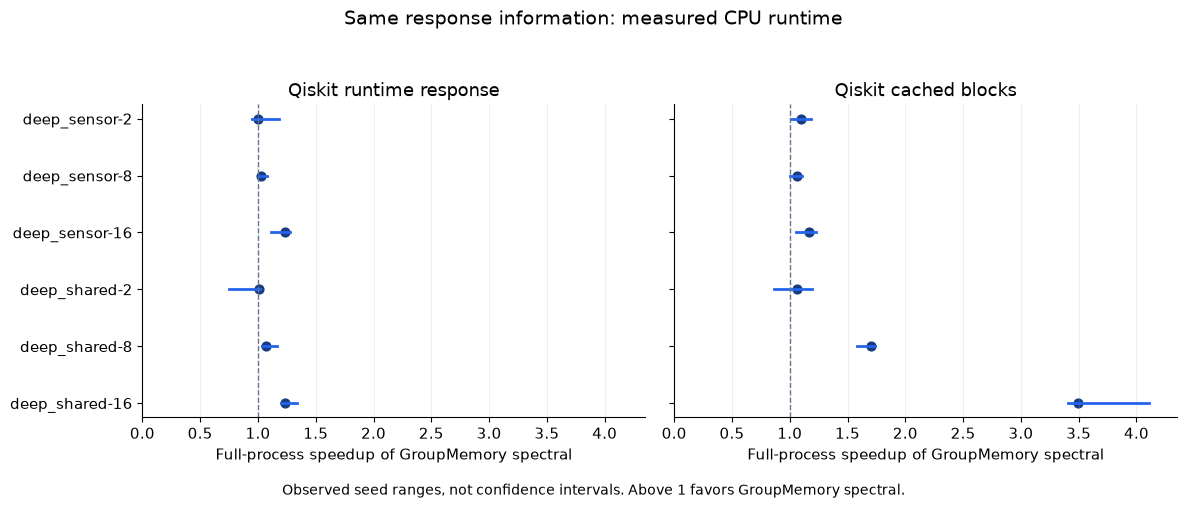

| Workload | Qiskit response ratio | Meets rule | Qiskit blocks ratio | Meets rule |
|---|---:|---|---:|---|
| deep_sensor-2 | 0.996× | False | 1.100× | True |
| deep_sensor-8 | 1.029× | False | 1.059× | True |
| deep_sensor-16 | 1.231× | True | 1.168× | True |
| deep_shared-2 | 1.006× | False | 1.059× | False |
| deep_shared-8 | 1.070× | True | 1.706× | True |
| deep_shared-16 | 1.236× | True | 3.495× | True |

In [4]:
baselines = ("qiskit_response", "qiskit_blocks")
maximum = max(comparisons[c, b]["maximum_seed_speedup"] for c in conditions for b in baselines)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, baseline in zip(axes, baselines):
    for i, cid in enumerate(conditions):
        r = comparisons[cid, baseline]
        ax.plot([r["minimum_seed_speedup"], r["maximum_seed_speedup"]], [i, i], color="#2563eb", lw=2)
        ax.scatter(r["paired_speedup"], i, color="#163c80", s=40)
    ax.axvline(1, color="#64748b", ls="--", lw=1)
    ax.set(xlim=(0, max(1.2, maximum)*1.06), xlabel="Full-process speedup of GroupMemory spectral",
           title=labels[baseline])
    ax.set_yticks(range(len(conditions)), conditions)
    ax.grid(axis="x", alpha=.2)
axes[0].invert_yaxis()
fig.suptitle("Same response information: measured CPU runtime", fontsize=14)
fig.text(.5, .01, "Observed seed ranges, not confidence intervals. Above 1 favors GroupMemory spectral.", ha="center", fontsize=10)
fig.tight_layout(rect=(0, .04, 1, .94))
fig.savefig(results / "notebook_paired_speedups.png", dpi=150)
plt.show()
lines = ["| Workload | Qiskit response ratio | Meets rule | Qiskit blocks ratio | Meets rule |", "|---|---:|---|---:|---|"]
for cid in conditions:
    a, b = [comparisons[cid, m] for m in baselines]
    lines.append(f"| {cid} | {a['paired_speedup']:.3f}× | {a['descriptive_win']} | {b['paired_speedup']:.3f}× | {b['descriptive_win']} |")
display(Markdown("\n".join(lines)))


### Conservative comparison with the faster Qiskit control

This additional readout chooses the faster Qiskit median separately within each seed,
then forms the paired speed ratio. It does not choose a favorable baseline after pooling
timings. It is stricter than requiring separate wins against both implementations.


In [5]:
envelope = json.loads((results / "strongest_control_comparisons.json").read_text())
lines = ["| Workload | Speedup vs faster Qiskit control | Observed seed range | Meets rule |",
         "|---|---:|---:|---|"]
for recorded in envelope:
    cid = recorded["condition"]
    ratios = []
    for seed in config["seeds"]:
        med = {m: statistics.median(blocks[cid, seed, rep][m]["process_wall_s"]
                                   for rep in range(config["repeats"]))
               for m in ("group_spectral", "qiskit_response", "qiskit_blocks")}
        ratios.append(min(med["qiskit_response"], med["qiskit_blocks"]) / med["group_spectral"])
    assert abs(statistics.median(ratios) - recorded["paired_speedup"]) < 1e-12
    assert (min(ratios) > 1 and statistics.median(1-1/r for r in ratios) >= .05
            and len(ratios) >= 5 and config["repeats"] >= 3) == recorded["descriptive_win"]
    lines.append(f"| {cid} | {recorded['paired_speedup']:.3f}× | "
                 f"{min(ratios):.3f}–{max(ratios):.3f}× | {recorded['descriptive_win']} |")
display(Markdown("\n".join(lines)))


| Workload | Speedup vs faster Qiskit control | Observed seed range | Meets rule |
|---|---:|---:|---|
| deep_sensor-2 | 0.996× | 0.947–1.180× | False |
| deep_sensor-8 | 1.015× | 1.000–1.079× | False |
| deep_sensor-16 | 1.168× | 1.055–1.230× | True |
| deep_shared-2 | 1.006× | 0.745–1.020× | False |
| deep_shared-8 | 1.070× | 1.034–1.167× | True |
| deep_shared-16 | 1.236× | 1.196–1.341× | True |

### Total runtime across the tested depths

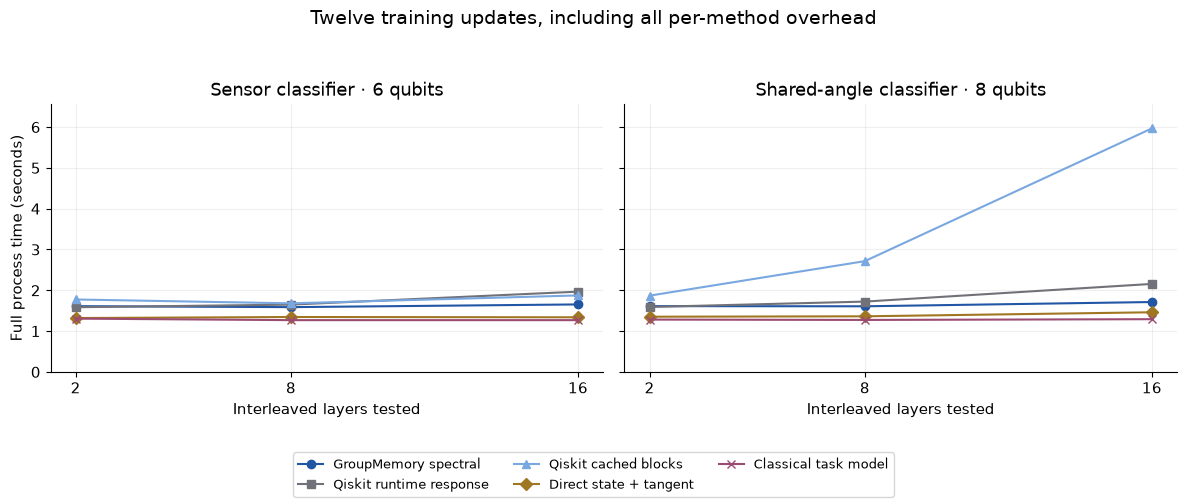

In [6]:
plotted = ("group_spectral", "qiskit_response", "qiskit_blocks", "classical_direct", "classical")
colors = ("#2156a5", "#71717a", "#79a7df", "#a17622", "#9b4b72")
markers = ("o", "s", "^", "D", "x")
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, family, title in zip(axes, ("deep_sensor", "deep_shared"),
                            ("Sensor classifier · 6 qubits", "Shared-angle classifier · 8 qubits")):
    chosen = [c for c in conditions if c.startswith(family)]
    depths = [int(c.rsplit("-", 1)[1]) for c in chosen]
    for method, color, marker in zip(plotted, colors, markers):
        ax.plot(depths, [summary[c, method]["process_wall_s"] for c in chosen],
                color=color, marker=marker, label=labels[method])
    ax.set(xticks=depths, xlabel="Interleaved layers tested", title=title)
    ax.grid(alpha=.2)
axes[0].set_ylim(0, 1.1 * max(summary[c, m]["process_wall_s"] for c in conditions for m in plotted))
axes[0].set_ylabel("Full process time (seconds)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=9)
fig.suptitle("Twelve training updates, including all per-method overhead", fontsize=14)
fig.tight_layout(rect=(0, .13, 1, .94))
fig.savefig(results / "notebook_absolute_runtime.png", dpi=150)
plt.show()


## Mechanism, memory and limitations

The batched-grid ablation separates ordinary batched matrix execution from coefficient
sharing. Faster spectral response construction is a software/simulator result that
other packages could adopt. Dense block matrices require \(O(4^n)\) storage, and Fourier
state coefficients \(O(B(L+1)2^n)\). The coefficient counter below is the largest
tracked coefficient array, **not** peak resident memory; the measured process RSS also
includes libraries and temporary storage.

Fewer native Aer calls do not establish fewer physical CNOTs. Both spectral arithmetic
and batched state propagation are classical work; the logical circuit is unchanged.


In [7]:
lines = ["| Workload | Source / native depth | Native CX per circuit | Spectral build (s) | Qiskit build (s) | Peak coefficient array | Worker peak RSS | Spectral speedup vs grid |",
         "|---|---:|---:|---:|---:|---:|---:|---:|"]
for cid in conditions:
    selected = [r for r in rows if r["spec"]["condition"] == cid]
    gm = [r for r in selected if r["method"] == "group_spectral"]
    q = [r for r in selected if r["method"] == "qiskit_response"]
    d = gm[0]["diagnostics"]["response"]
    build = lambda rr: statistics.median(r["diagnostics"]["response"]["calibration_seconds"] for r in rr)
    peak = max(r["diagnostics"]["response"]["peak_coefficient_bytes"] for r in gm)
    rss = statistics.median(r["peak_rss_bytes"] for r in gm)
    grid_ratio = comparisons[cid, "group_grid"]["paired_speedup"]
    lines.append(f"| {cid} | {d['source_depth']} / {d['native_depth']} | {d['native_cx_per_circuit']} | "
                 f"{build(gm):.4f} | {build(q):.4f} | {peak/1024:.0f} KiB | {rss/1024**2:.1f} MiB | {grid_ratio:.3f}× |")
display(Markdown("\n".join(lines)))


| Workload | Source / native depth | Native CX per circuit | Spectral build (s) | Qiskit build (s) | Peak coefficient array | Worker peak RSS | Spectral speedup vs grid |
|---|---:|---:|---:|---:|---:|---:|---:|
| deep_sensor-2 | 14 / 40 | 12 | 0.0063 | 0.0140 | 48 KiB | 210.9 MiB | 1.009× |
| deep_sensor-8 | 46 / 128 | 48 | 0.0141 | 0.0782 | 144 KiB | 218.8 MiB | 0.997× |
| deep_sensor-16 | 88 / 243 | 96 | 0.0265 | 0.2517 | 272 KiB | 211.1 MiB | 1.003× |
| deep_shared-2 | 16 / 48 | 16 | 0.0099 | 0.0220 | 192 KiB | 213.3 MiB | 0.975× |
| deep_shared-8 | 52 / 156 | 64 | 0.0278 | 0.1474 | 576 KiB | 217.1 MiB | 1.010× |
| deep_shared-16 | 102 / 303 | 128 | 0.0581 | 0.4872 | 1088 KiB | 215.6 MiB | 1.024× |

### Correctness repair in the dense-block control

The installed Aer fixture mishandles read-only NumPy matrix buffers. Writable copies
made once during setup restore correct results while retaining runtime parameter binding.
Their cost is included. This is a tested version/fixture observation, not a claim about
every Qiskit circuit. The saved reproducer reports both binding modes and does not require
future versions to retain the bug.


In [8]:
regression = json.loads((results / "binding_regression.json").read_text())
print(json.dumps(regression, indent=2))


{
  "scope": "Exact local CPU fixture; not a universal Aer or parameter-binding claim",
  "n_qubits": 4,
  "layers": 3,
  "input_seed": 9,
  "inputs": [
    [
      -0.8028369359828766,
      0.2428499070790021,
      -1.656345427042233,
      0.656104877556666
    ],
    [
      1.1434530226920894,
      -0.45261100300789897,
      0.4304857455543092,
      0.25093256908418204
    ]
  ],
  "theta": [
    0.317,
    -0.583
  ],
  "native_mean_z": [
    0.5581691958997277,
    0.6961398054516511
  ],
  "source_sha256": "222b8dba2f8683140825c29b95537ffec2e8cd493132731963fa88fccc97cc3e",
  "native_sha256": "2a2b72017076451306ab86c24122391713a7102f2484d01c58963c5961b1eba9",
  "fixed_block_sha256": [
    "3035071d80c08e29a762788e53410ad30f96619ac8c0efc50a7161d2e346ea25",
    "13f5b9ef7f8a5cc2864b782ea56007e9841b320a2c9bb5832d270adefabd508b"
  ],
  "versions": {
    "numpy": "2.5.4",
    "qiskit": "2.6.0",
    "qiskit-aer": "0.17.2"
  },
  "output_atol": 1e-10,
  "state_fidelity_minimum": 0.

## Complete timing ledger and takeaways

The primary comparison includes all per-method runtime. Tests, the checkpoint/resume
pilot, parent orchestration and readout have separate receipts rather than being
silently omitted or arbitrarily allocated to one method. Installation and development
time are excluded from benchmark timings.

Synthetic task accuracy and computational savings answer different questions. Sensor
test views share underlying base patterns. A few successful seeds and one shared angle
do not establish general QML scaling, quantum learning advantage, or LLM feasibility.


In [9]:
ledger = json.loads((results / "wall_accounting.json").read_text())
display(Markdown(f"Main benchmark including parent process: **{ledger['main_external_wall_s']/60:.2f} minutes**. "
                 f"Worker clocks sum to **{analysis['sum_process_wall_s']/60:.2f} minutes**."))
print(json.dumps(ledger, indent=2))


Main benchmark including parent process: **17.11 minutes**. Worker clocks sum to **17.07 minutes**.

{
  "main_external_wall_s": 1026.3548283329583,
  "main_worker_wall_sum_s": 1024.3828477845527,
  "main_parent_overhead_s": 1.9719805484055541,
  "main_loop_wall_s": 1026.0646807919838,
  "preflight_external_s": 26.247706249996554,
  "pilot_elapsed_including_resume_pause_s": 78.07096910476685,
  "pilot_worker_wall_sum_s": 66.01550395903178,
  "main_report_s": 1.4474888329859823,
  "pilot_report_s": 1.3993261249852367,
  "binding_regression_s_excluding_imports": 0.09225266601424664,
  "scope": "Full parent and fresh-worker process clocks. Per-method times include imports, data, compilation, fixed-block construction and copies, response construction/checks, bookkeeping, training, prediction, serialization and shutdown. Preflight, pilot, quick validation and readout are separate. Installation and development excluded. Notebook/export and final packaging have separate receipts.",
  "quick_external_wall_s": 23.12786595802754,
  "quick_report_s": 0.5607339999987744,
  "initial_packaging_s": 